In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("emails.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())


First Five Records:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset Shape: (5172, 3002)

Dataset Info

In [3]:
# Remove duplicate and missing records
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

# Separate features and target
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"].astype(int)

print("\nClass Distribution:")
print(y.value_counts())

print("\n0 = Normal (Not Spam)")
print("1 = Abnormal (Spam)")


Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64

0 = Normal (Not Spam)
1 = Abnormal (Spam)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [5]:
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="cosine",
    algorithm="brute",
    weights="distance"
)

knn.fit(X_train, y_train)

knn_predictions = knn.predict(X_test)

print("\nKNN Model Trained Successfully!")


KNN Model Trained Successfully!


In [6]:
svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

svm.fit(X_train, y_train)

svm_predictions = svm.predict(X_test)

print("\nSVM Model Trained Successfully!")


SVM Model Trained Successfully!


In [7]:
# CELL 7: EVALUATE KNN

knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_precision = precision_score(y_test, knn_predictions)
knn_recall = recall_score(y_test, knn_predictions)
knn_f1 = f1_score(y_test, knn_predictions)
knn_error = 1 - knn_accuracy

print("\n========== KNN PERFORMANCE ==========")
print("Accuracy:", round(knn_accuracy * 100, 2), "%")
print("Error Rate:", round(knn_error * 100, 2), "%")
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1 Score:", round(knn_f1, 4))

print("\nKNN Classification Report:")
print(classification_report(y_test, knn_predictions))



========== KNN PERFORMANCE ==========
Accuracy: 89.18 %
Error Rate: 10.82 %
Precision: 0.8032
Recall: 0.83
F1 Score: 0.8164

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       735
           1       0.80      0.83      0.82       300

    accuracy                           0.89      1035
   macro avg       0.87      0.87      0.87      1035
weighted avg       0.89      0.89      0.89      1035




KNN Confusion Matrix:
[[674  61]
 [ 51 249]]


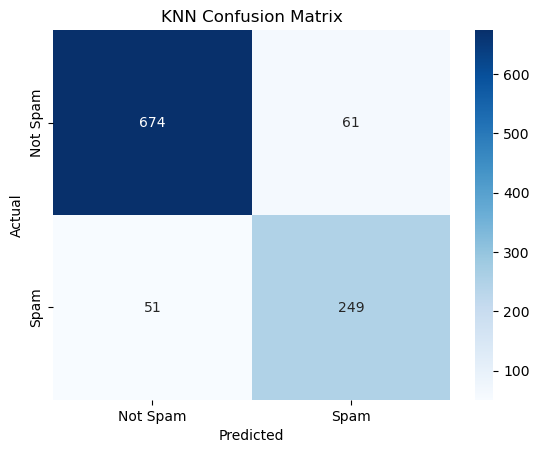

In [8]:
# CELL 8: KNN CONFUSION MATRIX

knn_cm = confusion_matrix(
    y_test, knn_predictions, labels=[0, 1]
)

print("\nKNN Confusion Matrix:")
print(knn_cm)

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [9]:
# CELL 9: EVALUATE SVM

svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(y_test, svm_predictions)
svm_recall = recall_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions)
svm_error = 1 - svm_accuracy

print("\n========== SVM PERFORMANCE ==========")
print("Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Error Rate:", round(svm_error * 100, 2), "%")
print("Precision:", round(svm_precision, 4))
print("Recall:", round(svm_recall, 4))
print("F1 Score:", round(svm_f1, 4))

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_predictions))


========== SVM PERFORMANCE ==========
Accuracy: 97.39 %
Error Rate: 2.61 %
Precision: 0.9505
Recall: 0.96
F1 Score: 0.9552

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       735
           1       0.95      0.96      0.96       300

    accuracy                           0.97      1035
   macro avg       0.97      0.97      0.97      1035
weighted avg       0.97      0.97      0.97      1035




SVM Confusion Matrix:
[[720  15]
 [ 12 288]]


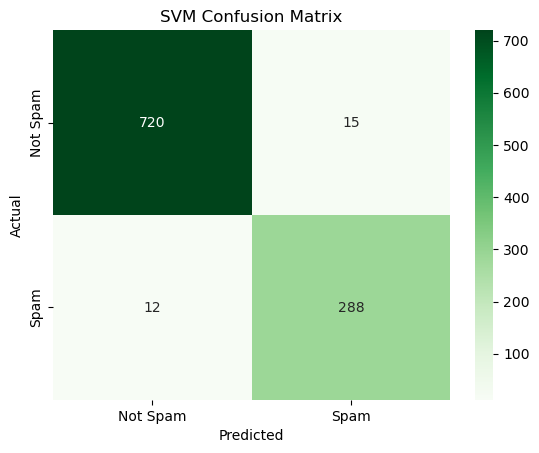

In [10]:
# CELL 10: SVM CONFUSION MATRIX

svm_cm = confusion_matrix(
    y_test, svm_predictions, labels=[0, 1]
)

print("\nSVM Confusion Matrix:")
print(svm_cm)

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [11]:
# CELL 11: MODEL COMPARISON

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Error Rate",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "KNN": [
        knn_accuracy,
        knn_error,
        knn_precision,
        knn_recall,
        knn_f1
    ],
    "SVM": [
        svm_accuracy,
        svm_error,
        svm_precision,
        svm_recall,
        svm_f1
    ]
})

In [12]:
print("\n========== MODEL COMPARISON ==========")
print(comparison.to_string(index=False))

if svm_f1 > knn_f1:
    print("\nBetter Performing Model: SVM")
else:
    print("\nBetter Performing Model: KNN")



========== MODEL COMPARISON ==========
    Metric      KNN      SVM
  Accuracy 0.891787 0.973913
Error Rate 0.108213 0.026087
 Precision 0.803226 0.950495
    Recall 0.830000 0.960000
  F1 Score 0.816393 0.955224

Better Performing Model: SVM


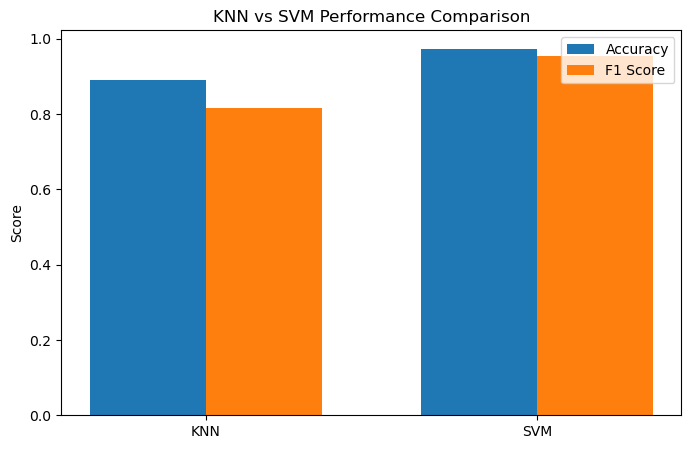

In [13]:
# CELL 12: PERFORMANCE COMPARISON GRAPH

models = ["KNN", "SVM"]

accuracies = [knn_accuracy, svm_accuracy]
f1_scores = [knn_f1, svm_f1]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    accuracies,
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    f1_scores,
    width,
    label="F1 Score"
)

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("KNN vs SVM Performance Comparison")
plt.legend()
plt.show()


In [15]:
# CELL 13: CLASSIFY A NEW EMAIL

def predict_email(email):

    # Convert input email into lowercase tokens
    words = re.findall(r"[a-z0-9']+", email.lower())

    # Count words that exist in the dataset vocabulary
    word_counts = {
        word: words.count(word)
        for word in set(words)
        if word in X.columns
    }

    # Create a feature vector in the same column order
    email_vector = pd.DataFrame(
        [[word_counts.get(col, 0) for col in X.columns]],
        columns=X.columns
    )
    # Check whether any known vocabulary words were found
    if email_vector.to_numpy().sum() == 0:
        print("\nWarning: No known dataset words found.")
        print("Prediction may not be meaningful.")
        return

    # Predict using both algorithms
    knn_result = knn.predict(email_vector)[0]
    svm_result = svm.predict(email_vector)[0]

    print("\nKNN Prediction:")
    if knn_result == 1:
        print("Abnormal State: SPAM")
    else:
        print("Normal State: NOT SPAM")

    print("\nSVM Prediction:")
    if svm_result == 1:
        print("Abnormal State: SPAM")
    else:
        print("Normal State: NOT SPAM")


In [16]:
new_email = input("\nEnter an email message to classify: ")

if new_email.strip():
    predict_email(new_email)
else:
    print("Please enter a valid email.")


Enter an email message to classify:  Congratulations! You have won a $10,000 lottery. Click here to claim your prize now!



KNN Prediction:
Abnormal State: SPAM

SVM Prediction:
Abnormal State: SPAM
